In [34]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [35]:
# Define State

class BMIState(TypedDict):

    weight: float
    height: float
    label_bmi: str
    BMI: float

In [36]:
def BMI_cal(state: BMIState) -> BMIState:

    w=state['weight']
    h=state['height']

    state['BMI']=w/(h**2)
    
    return state

In [37]:
def label_bmi(state: BMIState) -> BMIState:
    if state["BMI"] < 18.5:
        state["label_bmi"] = "Underweight"
    elif 18.5 <= state["BMI"] < 25:
        state["label_bmi"] ="Normal"
    elif 25 <= state["BMI"] < 30:
        state["label_bmi"] = "Overweight"
    else:
        state["label_bmi"] = "Obese"
    return state

In [38]:
# Define graph
graph = StateGraph(BMIState)

# Add state
graph.add_node("BMI_cal", BMI_cal)
graph.add_node("label_bmi", label_bmi)

# Add edges
graph.add_edge(START, "BMI_cal")
graph.add_edge("BMI_cal", "label_bmi")
graph.add_edge("label_bmi", END)

# Complile Graph
workflow = graph.compile()


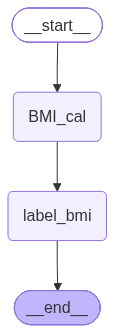

In [39]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [ ]:
# Execute Graph
initial_state = {'weight':80, 'height':1.73}

Final_state = workflow.invoke(initial_state)

print(Final_state)

{'weight': 80, 'height': 1.73, 'label_bmi': 'Overweight', 'BMI': 26.729927495071667}


: 